# Phase 5 Checks: Track B Hierarchical Model

Verifies `src/processing/game_table.py`, `src/models/stochastic/hierarchical.py` and the saved fit from
`src/pipelines/fit_hierarchical.py`. Run `py -m src.pipelines.fit_hierarchical` first; sections 6-10 read its output.

**Sections**
1. Setup
2. Game table: counts, goalies, indices
3. Goalie offsets use no future games (no leakage)
4. Synthetic recovery: a fake league with known ratings *(the most important model check)*
5. Matched check vs Track A *(the strict agreement test)*
6. Real fit: sampler diagnostics
7. League terms: home ice and scoring level
8. Sanity: ratings vs goals and xG
9. Posterior predictive: is Poisson good enough?
10. Pooled Track B vs Track A (qualitative)
11. Why goals are less spread than Poisson: testing for score effects

Each check prints **PASS** or **CHECK**. A CHECK isn't always a bug; read the note next to it.
Sections 4 and 5 fit new models (about 1-3 minutes in total).

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az

from config.settings import OUTPUT_DIR
from src.data.db import get_connection
from src.processing.team_strength import team_game_xg
from src.processing.goalie import goalie_game_xg
from src.processing.game_table import build_game_table, starting_goalies, goalie_gamma
from src.models.stochastic.goalie import goalie_rating_as_of
from src.models.stochastic.toy_mcmc import league_baseline, pair_games
from src.models.stochastic.hierarchical import (
    FIT_SEASONS, GOAL_COLS, build_model, sample, sample_scores, simulate_league, team_ratings,
)
from src.pipelines.fit_hierarchical import diagnostics
%matplotlib inline

def check(label, ok, note=""):
    print(f"{'PASS ' if ok else 'CHECK'}  {label}" + (f"   ({note})" if note else ""))

def interval(x, level=0.90):
    return np.quantile(x, [(1 - level) / 2, 1 - (1 - level) / 2], axis=0)

def load_posterior(path):
    """Read a saved posterior fully into memory and close the file.

    az.from_netcdf keeps the file open while the notebook runs; on Windows that
    locks it, and fit_hierarchical.py --overwrite then can't replace it.
    """
    d = az.from_netcdf(path)
    d = d.load()
    if hasattr(d, "close"):
        d.close()
    return d

def draws(post, name):
    """All chains pooled: (n_draws,) for a scalar, (n_draws, n_teams) for a team term."""
    x = post[name].values
    return x.reshape(-1, *x.shape[2:])

# Pair for the Track A comparisons (needs output/posteriors/toy_<A>_<B>.nc from fit_toy.py)
TEAM_A, TEAM_B = "COL", "DAL"

POSTERIOR_DIR = OUTPUT_DIR / "posteriors"
FIT_PATH = POSTERIOR_DIR / f"hier_{min(FIT_SEASONS)}_{max(FIT_SEASONS)}.nc"
TOY_PATH = POSTERIOR_DIR / f"toy_{TEAM_A}_{TEAM_B}.nc"

conn = get_connection()
tg = team_game_xg(conn)
gt, teams = build_game_table(conn, FIT_SEASONS)
idata = load_posterior(FIT_PATH)
post = idata.posterior
print(f"games: {len(gt):,}   teams: {len(teams)}   fit file: {FIT_PATH.name}")

games: 2,624   teams: 32   fit file: hier_20242025_20252026.nc


## 2. Game table: counts, goalies, indices

In [2]:
home_rows = tg[(tg["is_home"] == 1) & tg["season"].astype(str).isin(FIT_SEASONS)]
check("one row per game", gt["game_id"].is_unique)
check("row count matches team_game_xg home rows", len(gt) == len(home_rows), f"{len(gt):,} vs {len(home_rows):,}")
check("home and away differ in every game", (gt["home"] != gt["away"]).all())

missing = gt[["home_goalie", "away_goalie"]].isna().sum()
check("starting goalie found for >99% of sides", missing.sum() / (2 * len(gt)) < 0.01,
      f"missing home {missing.home_goalie}, away {missing.away_goalie}")
check("team indices run 0..n-1", gt["home_idx"].min() == 0 and gt["home_idx"].max() == len(teams) - 1)
check("indices point back to the right team",
      all(teams[i] == t for i, t in zip(gt["home_idx"], gt["home"])) and
      all(teams[i] == t for i, t in zip(gt["away_idx"], gt["away"])))

merged = gt.merge(home_rows[["game_id", "gf_xg", "ga_xg"]], on="game_id")
check("goals match team_game_xg (gf_xg / ga_xg)",
      (merged.home_goals == merged.gf_xg).all() and (merged.away_goals == merged.ga_xg).all())

ot_goals = (gt.home_goals + gt.away_goals) - (gt.home_goals_reg + gt.away_goals_reg)
check("regulation goals never exceed periods 1-4 goals",
      (gt.home_goals_reg <= gt.home_goals).all() and (gt.away_goals_reg <= gt.away_goals).all())
check("periods 1-4 add at most 1 goal (sudden-death OT)", ot_goals.isin([0, 1]).all(),
      f"{(ot_goals == 1).mean():.1%} of games decided by an OT goal")
# An OT goal after an untied regulation can only come from removed empty-net goals
# (e.g. a leader scores into the empty net, then the trailer scores twice to tie).
odd = (ot_goals == 1) & (gt.home_goals_reg != gt.away_goals_reg)
check("OT goals almost only in games tied after regulation (< 1% exceptions)", odd.mean() < 0.01,
      f"{odd.sum()} games: regulation tie hidden by a removed empty-net goal")
tied_reg = (gt.home_goals_reg == gt.away_goals_reg).mean()
check("tied after regulation in 18-28% of games (NHL norm)", 0.18 <= tied_reg <= 0.28, f"{tied_reg:.1%}")

g = pd.concat([gt.gamma_home, gt.gamma_away])
zero_share = (g == 0).mean()
check("gamma averages about 0 (|mean| < 0.02)", abs(g.mean()) < 0.02, f"mean {g.mean():+.4f}")
check("gamma range plausible (|gamma| < 0.15)", g.abs().max() < 0.15, f"min {g.min():+.3f}, max {g.max():+.3f}")
check("few goalies without history (< 5% of sides)", zero_share < 0.05, f"{zero_share:.1%}")

counts = pd.concat([gt.home, gt.away]).value_counts()
print(f"\ngames per team: {counts.min()}-{counts.max()}   regulation goals/game home {gt.home_goals_reg.mean():.3f}, "
      f"away {gt.away_goals_reg.mean():.3f}")
display(gt.head())

PASS   one row per game
PASS   row count matches team_game_xg home rows   (2,624 vs 2,624)
PASS   home and away differ in every game
PASS   starting goalie found for >99% of sides   (missing home 0, away 0)
PASS   team indices run 0..n-1
PASS   indices point back to the right team
PASS   goals match team_game_xg (gf_xg / ga_xg)
PASS   regulation goals never exceed periods 1-4 goals
PASS   periods 1-4 add at most 1 goal (sudden-death OT)   (15.3% of games decided by an OT goal)
PASS   OT goals almost only in games tied after regulation (< 1% exceptions)   (1 games: regulation tie hidden by a removed empty-net goal)
PASS   tied after regulation in 18-28% of games (NHL norm)   (23.7%)
PASS   gamma averages about 0 (|mean| < 0.02)   (mean +0.0050)
PASS   gamma range plausible (|gamma| < 0.15)   (min -0.050, max +0.066)
PASS   few goalies without history (< 5% of sides)   (0.3%)

games per team: 164-164   regulation goals/game home 2.867, away 2.679


,game_id,game_date,season,home,away,home_idx,away_idx,home_goals,away_goals,home_goals_reg,away_goals_reg,home_goalie,away_goalie,gamma_home,gamma_away
0,2024020001,2024-10-04,20242025,BUF,NJD,2,15,1,3,1,3,8480045,8474593,0.000285,0.008625
1,2024020002,2024-10-05,20242025,NJD,BUF,15,2,3,1,3,1,8474596,8482221,-0.017553,0.005624
2,2024020003,2024-10-08,20242025,SEA,STL,22,24,2,3,2,3,8475831,8476412,-0.013385,0.007599
3,2024020004,2024-10-08,20242025,FLA,BOS,11,1,6,4,6,4,8475683,8476914,0.002371,-0.011345
4,2024020005,2024-10-08,20242025,UTA,CHI,27,6,4,2,4,2,8478971,8475852,0.014126,0.002886


## 3. Goalie offsets use no future games

Recompute one mid-window starter's gamma from a goalie table cut off **before** the game date.
If the result is identical, the rating could not have seen that game or anything after it.

In [3]:
gg = goalie_game_xg(conn)
row = gt.iloc[len(gt) // 2]
date = row["game_date"]

past_only = gg[pd.to_datetime(gg["game_date"]) < date]
r = goalie_rating_as_of(past_only, date).set_index("goalie_id")
by_hand = -np.log(r.loc[row["home_goalie"], "theta_mean"]) if row["home_goalie"] in r.index else 0.0

print(f"{row['game_date'].date()}  {row['away']} @ {row['home']}  home goalie {row['home_goalie']}")
print(f"gamma in table {row['gamma_home']:+.6f}   recomputed from past games only {by_hand:+.6f}")
check("gamma uses only games before the date", np.isclose(row["gamma_home"], by_hand))

2025-10-07  CHI @ FLA  home goalie 8475683
gamma in table +0.008490   recomputed from past games only +0.008490
PASS   gamma uses only games before the date


## 4. Synthetic recovery: a fake league with known ratings

Three fake 32-team leagues (about 2,500 games each, like the real window), each fit with the real model.
Across the 3 x 64 team effects, about 90% of the 90% intervals should contain the true value.
League terms, including the tie parameter rho (true value 0.5), should mostly land inside their
intervals. Takes 2-5 minutes.

In [4]:
SEEDS = [11, 12, 13]
hits, league_hits, fits = [], [], []
for seed in SEEDS:
    sim, sim_teams, truth = simulate_league(games_per_pair=5, sigma_off=0.065, sigma_def=0.065,
                                            alpha0=0.99, alpha_home=0.07, rho=0.5, seed=seed)
    sim_idata = sample(build_model(sim, sim_teams), seed=seed, progressbar=False)
    sp = sim_idata.posterior
    for name in ["mu_off", "mu_def"]:
        lo, hi = interval(draws(sp, name))
        hits.append((lo <= truth[name]) & (truth[name] <= hi))
    row = {"seed": seed, "games": len(sim), "divergences": int(sim_idata.sample_stats["diverging"].values.sum())}
    for name in ["alpha0", "alpha_home", "sigma_off", "sigma_def", "rho"]:
        x = draws(sp, name); lo, hi = interval(x)
        row[name] = f"{x.mean():.3f} [{lo:.3f}, {hi:.3f}] true {truth[name]:.3f}"
        league_hits.append(lo <= truth[name] <= hi)
    fits.append(row)

display(pd.DataFrame(fits))
cover = np.concatenate(hits).mean()
check("team effects: 84-95% of 90% intervals cover the truth", 0.84 <= cover <= 0.95,
      f"{cover:.1%} of {np.concatenate(hits).size}")
check("league terms: at least 12 of 15 intervals cover the truth", sum(league_hits) >= 12,
      f"{sum(league_hits)}/15")
check("no divergences in any synthetic fit", all(f["divergences"] == 0 for f in fits))

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [alpha0, alpha_home, sigma_off, sigma_def, z_off, z_def, tau]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 45 seconds.
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [alpha0, alpha_home, sigma_off, sigma_def, z_off, z_def, tau]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 46 seconds.
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [alpha0, alpha_home, sigma_off, sigma_def, z_off, z_def, tau]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 47 seconds.


,seed,games,divergences,alpha0,alpha_home,sigma_off,sigma_def,rho
0,11,2480,0,"0.978 [0.948, 1.008] true 0.990","0.051 [0.020, 0.081] true 0.070","0.053 [0.032, 0.076] true 0.065","0.052 [0.030, 0.075] true 0.065","0.610 [0.488, 0.741] true 0.500"
1,12,2480,0,"0.974 [0.943, 1.003] true 0.990","0.083 [0.054, 0.113] true 0.070","0.050 [0.028, 0.072] true 0.065","0.050 [0.028, 0.073] true 0.065","0.444 [0.336, 0.560] true 0.500"
2,13,2480,0,"1.008 [0.969, 1.046] true 0.990","0.054 [0.024, 0.084] true 0.070","0.086 [0.064, 0.114] true 0.065","0.066 [0.045, 0.091] true 0.065","0.538 [0.419, 0.665] true 0.500"


PASS   team effects: 84-95% of 90% intervals cover the truth   (88.5% of 192)
PASS   league terms: at least 12 of 15 intervals cover the truth   (15/15)
PASS   no divergences in any synthetic fit


## 5. Matched check vs Track A

Track B in matched mode (no pooling, alpha0 and home ice fixed to Track A's values, no goalie term) on the
**same** head-to-head games and the **same goals** Track A used (periods 1-4, not regulation only). The posteriors of $d_A = \mu_{off,A} - \mu_{def,B}$ and
$d_B = \mu_{off,B} - \mu_{def,A}$ should match Track A within Monte Carlo error.
The priors differ slightly (Track A: uniform on [-1, 1]; matched Track B: N(0, 1) on each team term,
so N(0, 2) on each d), which moves the mean by about 0.001 here.

In [5]:
toy = load_posterior(TOY_PATH)
a0_toy, eta_toy = float(toy.posterior.attrs["alpha0"]), float(toy.posterior.attrs["eta"])

# Track A's games in game-table form: teams [A, B] -> indices 0, 1
pg = pair_games(tg, TEAM_A, TEAM_B)
pair = pd.DataFrame({
    "game_id": pg.game_id,
    "home_idx": np.where(pg.a_home == 1, 0, 1),
    "away_idx": np.where(pg.a_home == 1, 1, 0),
    "home_goals": np.where(pg.a_home == 1, pg.goals_a, pg.goals_b),
    "away_goals": np.where(pg.a_home == 1, pg.goals_b, pg.goals_a),
    "gamma_home": 0.0, "gamma_away": 0.0,
})
check("same number of games as Track A", len(pair) == toy.observed_data["goals_a"].size, f"{len(pair)}")

m_idata = sample(build_model(pair, [TEAM_A, TEAM_B], matched=True, alpha0=a0_toy, alpha_home=eta_toy,
                             goal_cols=("home_goals", "away_goals")),
                 seed=5, draws=4000, progressbar=False)
mp = m_idata.posterior
off, dfn = draws(mp, "mu_off"), draws(mp, "mu_def")
track_b = {"d_A": off[:, 0] - dfn[:, 1], "d_B": off[:, 1] - dfn[:, 0]}

for name in ["d_A", "d_B"]:
    a = toy.posterior[name].values.ravel()
    b = track_b[name]
    print(f"{name}: Track A {a.mean():+.4f} sd {a.std():.4f} 90% {interval(a).round(3)}   "
          f"Track B {b.mean():+.4f} sd {b.std():.4f} 90% {interval(b).round(3)}")
    check(f"{name} means agree (within 0.01)", abs(a.mean() - b.mean()) < 0.01)
    check(f"{name} sds agree (within 5%)", abs(b.std() / a.std() - 1) < 0.05)
check("no divergences in the matched fit", int(m_idata.sample_stats["diverging"].values.sum()) == 0)

Initializing NUTS using jitter+adapt_diag...


PASS   same number of games as Track A   (18)


Sequential sampling (4 chains in 1 job)
NUTS: [z_off, z_def]
Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 9 seconds.


d_A: Track A +0.1141 sd 0.1307 90% [-0.106  0.325]   Track B +0.1113 sd 0.1297 90% [-0.106  0.32 ]
PASS   d_A means agree (within 0.01)
PASS   d_A sds agree (within 5%)
d_B: Track A -0.0553 sd 0.1427 90% [-0.296  0.173]   Track B -0.0525 sd 0.1416 90% [-0.291  0.175]
PASS   d_B means agree (within 0.01)
PASS   d_B sds agree (within 5%)
PASS   no divergences in the matched fit


## 6. Real fit: sampler diagnostics

Same checks `fit_hierarchical.py` printed, re-run on the saved file, plus traces and the one known
soft spot: alpha0 trading off against the average team effect. Some correlation is expected
(the data only pin down their sum); it only matters if it slows mixing. If alpha0's ESS is low,
switch the team effects to `pm.ZeroSumNormal`.

PASS   R-hat < 1.01 (all parameters)   (worst 1.0037)
PASS   ESS > 400 (all parameters)   (smallest 1,570)
PASS   no divergences   (0)
PASS   BFMI > 0.3 (every chain)   (0.66, 0.71, 0.64, 0.62)
correlation of alpha0 with the average team effect: r = -0.81 (expected to be negative)
PASS   alpha0 mixes well despite that (ESS > 1,000)   (ESS 2,239)


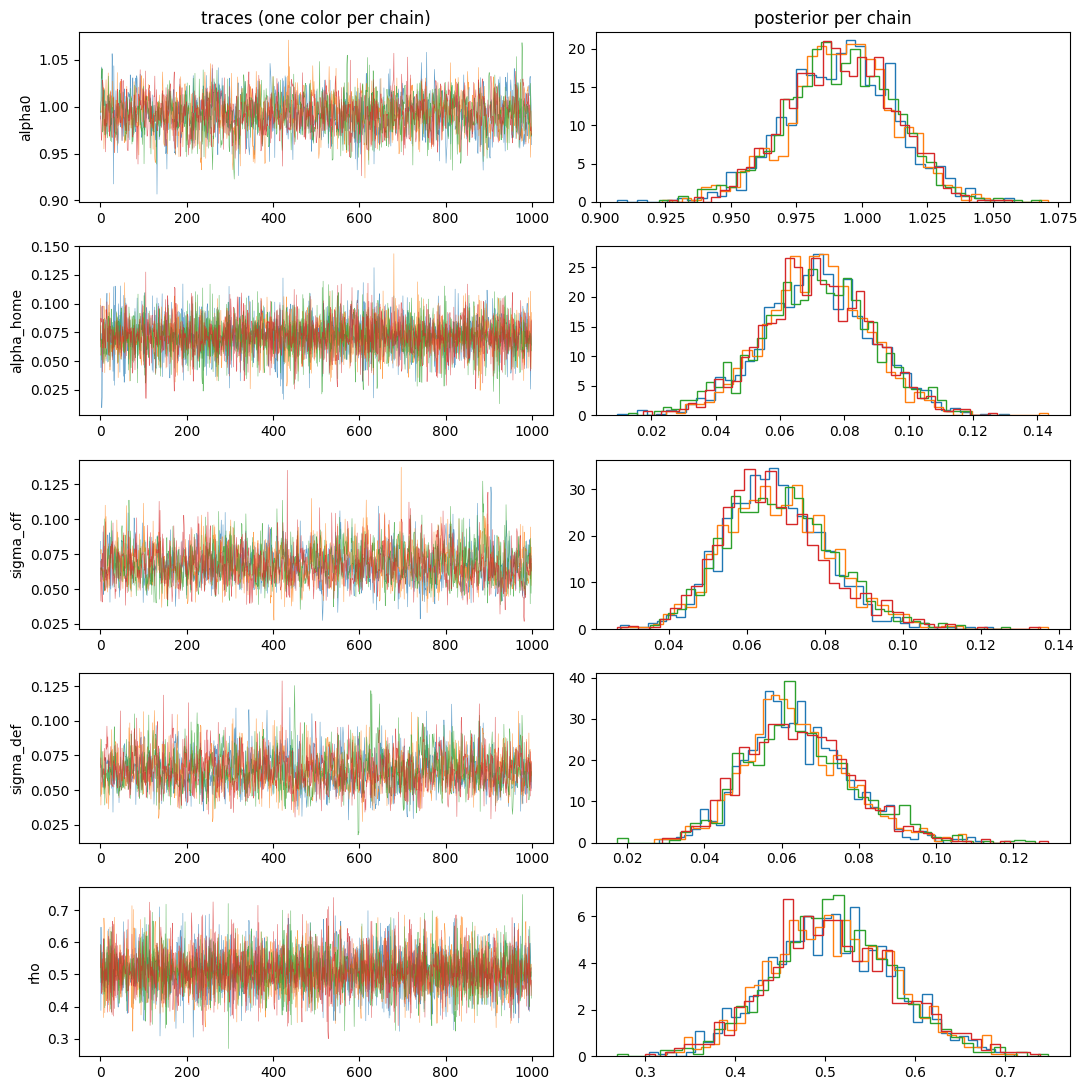

In [6]:
diag = diagnostics(idata)

avg_team = draws(post, "mu_off").mean(axis=1) - draws(post, "mu_def").mean(axis=1)
r = np.corrcoef(draws(post, "alpha0"), avg_team)[0, 1]
ess_a0 = diag["variables"]["alpha0"]["min_ess"]
print(f"correlation of alpha0 with the average team effect: r = {r:+.2f} (expected to be negative)")
check("alpha0 mixes well despite that (ESS > 1,000)", ess_a0 > 1000, f"ESS {ess_a0:,.0f}")

names = ["alpha0", "alpha_home", "sigma_off", "sigma_def", "rho"]
fig, axes = plt.subplots(len(names), 2, figsize=(11, 2.2 * len(names)))
for i, name in enumerate(names):
    x = post[name].values
    for c in range(x.shape[0]):
        axes[i, 0].plot(x[c], lw=0.4, alpha=0.7)
        axes[i, 1].hist(x[c], bins=40, histtype="step", density=True)
    axes[i, 0].set_ylabel(name)
axes[0, 0].set_title("traces (one color per chain)"); axes[0, 1].set_title("posterior per chain")
plt.tight_layout()

## 7. League terms: home ice and scoring level

Home ice from Track B should agree with the direct league ratio $\eta$ (the Phase 4 formula), computed on the
same games and the same regulation goals.

In [7]:
fit_tg = tg[tg["season"].astype(str).isin(FIT_SEASONS)]
h_col, a_col = GOAL_COLS
alpha0_direct = np.log(gt[a_col].mean())
eta_direct = np.log(gt[h_col].mean() / gt[a_col].mean())

for name, direct in [("alpha_home", eta_direct), ("alpha0", alpha0_direct)]:
    x = draws(post, name); lo, hi = interval(x)
    print(f"{name:10s} Track B {x.mean():+.4f} [{lo:+.4f}, {hi:+.4f}]   direct league value {direct:+.4f}")
check("home ice: direct eta inside Track B's 90% interval",
      interval(draws(post, "alpha_home"))[0] <= eta_direct <= interval(draws(post, "alpha_home"))[1])
check("alpha0 within 0.05 of log(away regulation goals/game)", abs(draws(post, "alpha0").mean() - alpha0_direct) < 0.05,
      "differs slightly because Track B also removes goalie offsets and schedule")
for name in ["sigma_off", "sigma_def"]:
    m = draws(post, name).mean()
    check(f"{name} plausible (0.02-0.20)", 0.02 < m < 0.20, f"{m:.3f}: a typical team is about ±{np.expm1(m):.0%}")

alpha_home Track B +0.0713 [+0.0426, +0.0989]   direct league value +0.0676
alpha0     Track B +0.9922 [+0.9582, +1.0250]   direct league value +0.9856
PASS   home ice: direct eta inside Track B's 90% interval
PASS   alpha0 within 0.05 of log(away regulation goals/game)   (differs slightly because Track B also removes goalie offsets and schedule)
PASS   sigma_off plausible (0.02-0.20)   (0.068: a typical team is about ±7%)
PASS   sigma_def plausible (0.02-0.20)   (0.064: a typical team is about ±7%)


## 8. Sanity: ratings vs goals and xG

Track B is fit on goals, so its net rating should track goal differential closely. It never sees xG,
so agreement with xG differential (Phase 2-3) is an independent check that the ratings mean something.

PASS   net rating tracks goal differential (r > 0.9)   (r = 0.998)
PASS   net rating tracks xG differential (r > 0.6)   (r = 0.776, independent of the fit)
PASS   offense tracks goals for (r > 0.8)   (r = 1.000)
PASS   defense tracks goals against (r > 0.8)   (r = 0.994)


,off_mean,def_mean,net_mean,net_lo,net_hi,goal_diff_pg,xg_diff_pg
team,,,,,,,
COL,0.087,0.096,0.183,0.087,0.285,0.762,0.605
TBL,0.090,0.073,0.164,0.073,0.258,0.689,0.379
DAL,0.073,0.062,0.136,0.041,0.234,0.579,0.155
VGK,0.061,0.043,0.104,0.011,0.200,0.433,0.501
CAR,0.072,0.028,0.101,0.008,0.196,0.421,0.616
WSH,0.052,0.028,0.080,-0.012,0.175,0.341,-0.058
WPG,0.002,0.056,0.058,-0.034,0.153,0.311,0.049
BUF,0.069,-0.017,0.052,-0.040,0.144,0.195,-0.111
OTT,0.028,0.022,0.051,-0.040,0.146,0.207,0.380


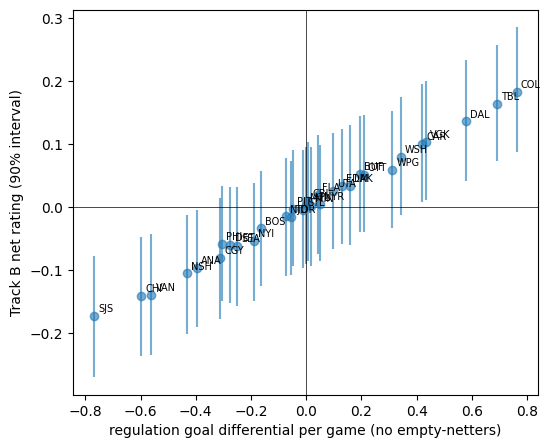

In [8]:
ratings = team_ratings(idata, teams)

sides = pd.concat([
    gt.assign(team=gt.home, gf=gt[h_col], ga=gt[a_col])[["game_id", "team", "gf", "ga"]],
    gt.assign(team=gt.away, gf=gt[a_col], ga=gt[h_col])[["game_id", "team", "gf", "ga"]],
])
per_team = (sides.groupby("team").agg(games=("game_id", "nunique"), gf=("gf", "sum"), ga=("ga", "sum"))
            .join(fit_tg.groupby("team").agg(xgf=("xgf", "sum"), xga=("xga", "sum"))))
per_team["goal_diff_pg"] = (per_team.gf - per_team.ga) / per_team.games
per_team["xg_diff_pg"] = (per_team.xgf - per_team.xga) / per_team.games
comp = ratings.set_index("team").join(per_team)

r_goals = comp.net_mean.corr(comp.goal_diff_pg)
r_xg = comp.net_mean.corr(comp.xg_diff_pg)
r_off = comp.off_mean.corr(comp.gf / comp.games)
r_def = comp.def_mean.corr(-comp.ga / comp.games)
check("net rating tracks goal differential (r > 0.9)", r_goals > 0.9, f"r = {r_goals:.3f}")
check("net rating tracks xG differential (r > 0.6)", r_xg > 0.6, f"r = {r_xg:.3f}, independent of the fit")
check("offense tracks goals for (r > 0.8)", r_off > 0.8, f"r = {r_off:.3f}")
check("defense tracks goals against (r > 0.8)", r_def > 0.8, f"r = {r_def:.3f}")

display(comp[["off_mean", "def_mean", "net_mean", "net_lo", "net_hi", "goal_diff_pg", "xg_diff_pg"]]
        .round(3).sort_values("net_mean", ascending=False))

fig, ax = plt.subplots(figsize=(6, 5))
ax.errorbar(comp.goal_diff_pg, comp.net_mean, yerr=[comp.net_mean - comp.net_lo, comp.net_hi - comp.net_mean],
            fmt="o", alpha=0.6)
for t, rr in comp.iterrows():
    ax.annotate(t, (rr.goal_diff_pg, rr.net_mean), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("regulation goal differential per game (no empty-netters)"); ax.set_ylabel("Track B net rating (90% interval)")
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)

## 9. Posterior predictive: does the model reproduce real scores?

Simulate every game again from 500 posterior draws and compare with what happened, using the fitted
**tie-inflated** model and, for comparison, the same rates with **plain Poisson** (rho = 0).
Goals are regulation only, so "tied after regulation" is games tied after 60 minutes (NHL about 22-24%).
Tie inflation should fix the tie and home-win rows. **variance / mean** is expected to stay slightly
below the simulated range: each team's goals are a bit less spread than Poisson (score effects:
trailing teams press, leaders sit back). That is a known v2 item, not a bug.

rho: mean 0.509, 90% [0.397 0.626] (ties 51% more likely than independent scoring)


,statistic,actual,model 90%,inside,plain Poisson 90%,inside (Poisson)
0,goals/team-game,2.7732,"[2.7237, 2.8215]",True,"[2.7442, 2.8434]",True
1,variance/mean,0.9221,"[0.9607, 1.0310]",False,"[0.9951, 1.0657]",False
2,share 0 goals,0.0522,"[0.0535, 0.0659]",False,"[0.0575, 0.0696]",False
3,share 5+ goals,0.1380,"[0.1366, 0.1553]",True,"[0.1444, 0.1639]",False
4,home win in regulation,0.4196,"[0.3929, 0.4329]",True,"[0.4260, 0.4680]",False
5,tied after regulation,0.2370,"[0.2188, 0.2557]",True,"[0.1589, 0.1822]",False


PASS   goals/team-game inside the model's simulated range
CHECK  variance/mean inside the model's simulated range   (expected: v2 item)
CHECK  share 0 goals inside the model's simulated range
PASS   share 5+ goals inside the model's simulated range
PASS   home win in regulation inside the model's simulated range
PASS   tied after regulation inside the model's simulated range


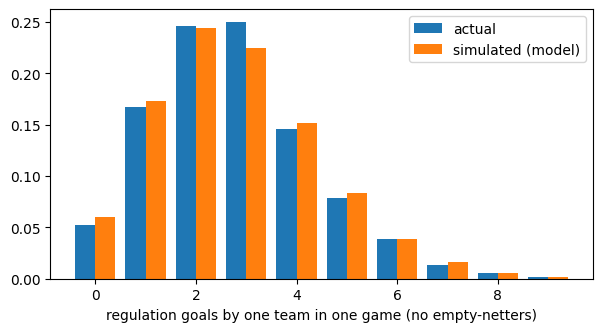

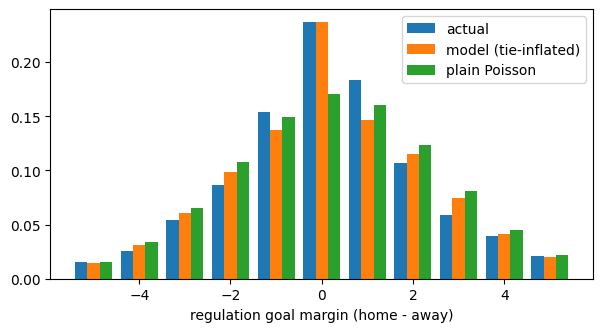

In [9]:
rng = np.random.default_rng(0)
n_draws = 500
pick = rng.choice(draws(post, "alpha0").size, n_draws, replace=False)

a0, ah = draws(post, "alpha0")[pick], draws(post, "alpha_home")[pick]
off, dfn = draws(post, "mu_off")[pick], draws(post, "mu_def")[pick]
hi_, ai_ = gt.home_idx.to_numpy(), gt.away_idx.to_numpy()
lam_h = np.exp(a0[:, None] + ah[:, None] + off[:, hi_] - dfn[:, ai_] - gt.gamma_away.to_numpy())
lam_a = np.exp(a0[:, None] + off[:, ai_] - dfn[:, hi_] - gt.gamma_home.to_numpy())
rho_draws = draws(post, "rho")[pick]
print(f"rho: mean {draws(post, 'rho').mean():.3f}, 90% {interval(draws(post, 'rho')).round(3)} "
      f"(ties {draws(post, 'rho').mean():.0%} more likely than independent scoring)")
sim_h, sim_a = sample_scores(lam_h, lam_a, rho_draws[:, None], rng)     # tie-inflated (the model)
pois_h, pois_a = rng.poisson(lam_h), rng.poisson(lam_a)                  # plain Poisson, same rates

def stats_of(h, a):
    goals = np.concatenate([h, a], axis=-1)
    return {"goals/team-game": goals.mean(axis=-1),
            "variance/mean": goals.var(axis=-1) / goals.mean(axis=-1),
            "share 0 goals": (goals == 0).mean(axis=-1),
            "share 5+ goals": (goals >= 5).mean(axis=-1),
            "home win in regulation": (h > a).mean(axis=-1),
            "tied after regulation": (h == a).mean(axis=-1)}

sim_stats = stats_of(sim_h, sim_a)
pois_stats = stats_of(pois_h, pois_a)
obs_stats = stats_of(gt[h_col].to_numpy()[None, :], gt[a_col].to_numpy()[None, :])
rows = []
for k in sim_stats:
    lo, hi = interval(sim_stats[k])
    obs = float(obs_stats[k][0])
    plo, phi = interval(pois_stats[k])
    rows.append({"statistic": k, "actual": round(obs, 4),
                 "model 90%": f"[{lo:.4f}, {hi:.4f}]", "inside": lo <= obs <= hi,
                 "plain Poisson 90%": f"[{plo:.4f}, {phi:.4f}]", "inside (Poisson)": plo <= obs <= phi})
ppc = pd.DataFrame(rows)
display(ppc)
for r_ in rows:
    note = "expected: v2 item" if r_["statistic"] == "variance/mean" else ""
    check(f"{r_['statistic']} inside the model's simulated range", r_["inside"], note)

obs_goals = np.concatenate([gt[h_col], gt[a_col]])
sim_goals = np.concatenate([sim_h, sim_a], axis=1)
k = np.arange(0, 10)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(k - 0.2, [(obs_goals == i).mean() for i in k], width=0.4, label="actual")
ax.bar(k + 0.2, [(sim_goals == i).mean() for i in k], width=0.4, label="simulated (model)")
ax.set_xlabel("regulation goals by one team in one game (no empty-netters)"); ax.legend()

# Regulation goal margin (home - away): where tie inflation shows up
m = np.arange(-5, 6)
obs_m = (gt[h_col] - gt[a_col]).to_numpy()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(m - 0.27, [(obs_m == i).mean() for i in m], width=0.27, label="actual")
ax.bar(m, [((sim_h - sim_a) == i).mean() for i in m], width=0.27, label="model (tie-inflated)")
ax.bar(m + 0.27, [((pois_h - pois_a) == i).mean() for i in m], width=0.27, label="plain Poisson")
ax.set_xlabel("regulation goal margin (home - away)"); ax.legend()

## 10. Pooled Track B vs Track A (qualitative)

The full model's $d_A, d_B$ for the same pair at neutral ice. It uses every team's games (2 seasons) and
partial pooling, so it should be much narrower and pulled toward 0. It usually sits inside Track A's wide
interval; a pooled mean far outside it is worth a look, not an automatic failure (different games, priors and goalies).

d_A: Track A +0.114 [-0.106, +0.325]   pooled Track B +0.025 [-0.072, +0.117]   narrower by 2.3x
PASS   d_A: pooled narrower than Track A
PASS   d_A: pooled mean inside Track A's interval   (qualitative)
d_B: Track A -0.055 [-0.296, +0.173]   pooled Track B -0.022 [-0.121, +0.075]   narrower by 2.4x
PASS   d_B: pooled narrower than Track A
PASS   d_B: pooled mean inside Track A's interval   (qualitative)


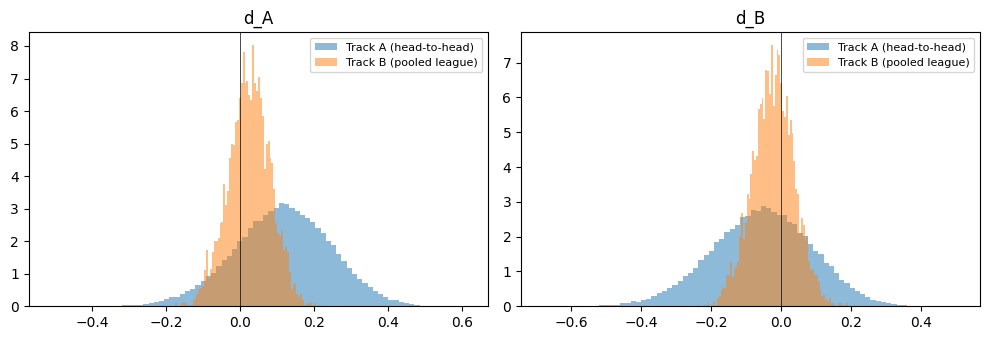

In [10]:
ia, ib = teams.index(TEAM_A), teams.index(TEAM_B)
off, dfn = draws(post, "mu_off"), draws(post, "mu_def")
pooled = {"d_A": off[:, ia] - dfn[:, ib], "d_B": off[:, ib] - dfn[:, ia]}

for name in ["d_A", "d_B"]:
    a = toy.posterior[name].values.ravel(); b = pooled[name]
    la, ha = interval(a); lb, hb = interval(b)
    print(f"{name}: Track A {a.mean():+.3f} [{la:+.3f}, {ha:+.3f}]   "
          f"pooled Track B {b.mean():+.3f} [{lb:+.3f}, {hb:+.3f}]   narrower by {(ha - la) / (hb - lb):.1f}x")
    check(f"{name}: pooled narrower than Track A", (hb - lb) < (ha - la))
    check(f"{name}: pooled mean inside Track A's interval", la <= b.mean() <= ha, "qualitative")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, name in zip(axes, ["d_A", "d_B"]):
    ax.hist(toy.posterior[name].values.ravel(), bins=80, density=True, alpha=0.5, label="Track A (head-to-head)")
    ax.hist(pooled[name], bins=80, density=True, alpha=0.5, label="Track B (pooled league)")
    ax.axvline(0, color="k", lw=0.5); ax.set_title(name); ax.legend(fontsize=8)
plt.tight_layout()

## 11. Why goals are less spread than Poisson: testing for score effects

Section 9 found each team's regulation goals less spread than Poisson (variance / mean 0.92, fewer shutouts).
The suspected cause is **score effects**: trailing teams press (and pull the goalie late), leading teams sit back.
Three tests, all from play-by-play:

1. **Dispersion by period.** Score effects need a score to act on, so the squeeze should build up during the game:
   variance / mean near Poisson after period 1, lower by the end of regulation. A flat value would point elsewhere.
2. **Scoring by score state.** Each team's goals while trailing / tied / leading, against what its own Track B rate
   predicts for that much time (so team quality is taken out). Score effects show as trailing > 1 > leading.
3. **Empty-net goals put back.** How much of the gap comes only from leaving empty-netters out.

Tested on simulated games: with built-in score effects all three show them; without, Tests 1 and 2 come back flat.

Test 1: variance / mean of each team's goals (no empty-netters), by periods included



,goals counted,goals/team-game,variance/mean,Poisson 90% (same team rates),inside
0,period 1,0.872,0.981,"[0.975, 1.037]",True
1,periods 1-2,1.894,0.960,"[0.979, 1.049]",False
2,periods 1-3 (regulation),2.773,0.922,"[0.986, 1.053]",False


PASS   dispersion falls as the game goes on (period 1 vs regulation)   (0.981 -> 0.922; flat would mean the squeeze is there from the start, i.e. not score effects)

Test 2: goals (no empty-netters) by score state. 'expected' uses each team's own Track B rate,
so team quality is taken out: 1.00 = scoring at the team's normal pace.



,score state,minutes,goals,goals/60,actual / expected,90% range of that ratio
0,trailing 2+,45958,2325,3.04,1.108,±0.038
1,trailing 1,57242,2831,2.97,1.069,±0.033
2,tied,108481,4858,2.69,0.964,±0.023
3,leading 1,57242,2515,2.64,0.939,±0.031
4,leading 2+,45958,2025,2.64,0.927,±0.034


PASS   trailing teams score faster than leading teams (down 1 vs up 1)   (1.07 vs 0.94 of normal pace)

Test 3: regulation variance / mean, with and without empty-net goals



,goals,goals/team-game,variance/mean,Poisson 90%
0,no empty-netters (what Track B fits),2.773,0.922,"[0.986, 1.053]"
1,with empty-netters,2.970,1.010,"[0.986, 1.053]"


Putting empty-net goals back closes 90% of the gap to the Poisson range.

Verdict: score effects confirmed: dispersion builds up during the game and trailing teams outscore their normal pace while leaders fall below it.


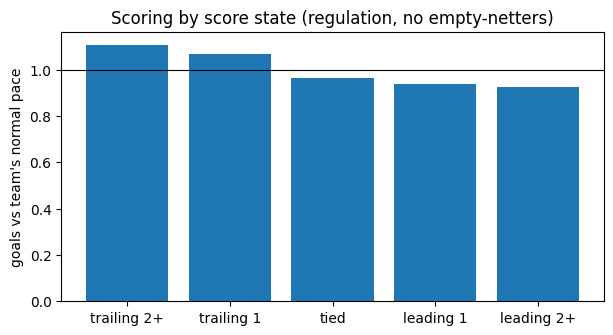

In [11]:
REG_SECONDS = 3 * 1200

# Every regulation goal in the fit window, in time order, flagged empty-net
# (a goal not in shot_xg = scored with the goalie pulled) and home/away.
goals = pd.read_sql("""
    SELECT  se.game_id, se.period, ge.game_seconds, ge.sort_order,
            CASE WHEN se.team_id = s.home_team_id THEN 1 ELSE 0 END AS is_home,
            CASE WHEN x.event_id IS NULL THEN 1 ELSE 0 END AS empty_net
    FROM    shot_events se
    JOIN    game_events ge ON ge.game_id = se.game_id AND ge.event_id = se.event_id
    JOIN    schedule s     ON s.game_id = se.game_id
    LEFT JOIN shot_xg x    ON x.game_id = se.game_id AND x.event_id = se.event_id
    WHERE   se.event_type = 'goal' AND se.period <= 3
""", conn)
goals = goals[goals.game_id.isin(gt.game_id)].sort_values(["game_id", "sort_order"]).reset_index(drop=True)

# Each game's regulation scoring rates from Track B (posterior means)
pm_ = {n: draws(post, n).mean(axis=0) for n in ["alpha0", "alpha_home", "mu_off", "mu_def"]}
lam_home_g = np.exp(pm_["alpha0"] + pm_["alpha_home"] + pm_["mu_off"][gt.home_idx] - pm_["mu_def"][gt.away_idx] - gt.gamma_away).to_numpy()
lam_away_g = np.exp(pm_["alpha0"] + pm_["mu_off"][gt.away_idx] - pm_["mu_def"][gt.home_idx] - gt.gamma_home).to_numpy()
lam = pd.DataFrame({"game_id": gt.game_id, "lam_home": lam_home_g, "lam_away": lam_away_g})

def team_game_counts(g, periods, include_en=False):
    """Goals per team-game (home and away stacked) in the given periods."""
    sel = g[g.period.isin(periods) & ((g.empty_net == 0) | include_en)]
    c = sel.groupby(["game_id", "is_home"]).size().unstack(fill_value=0).reindex(columns=[0, 1], fill_value=0)
    c = c.reindex(gt.game_id, fill_value=0)
    return np.concatenate([c[1].to_numpy(), c[0].to_numpy()])           # home then away, same order as lam

def vm(x):
    return x.var() / x.mean()

def poisson_reference(mean_target, n_sims=300, seed=0):
    """var/mean under Poisson with each team-game's Track B rate, scaled to the observed mean."""
    rates = np.concatenate([lam_home_g, lam_away_g])
    rates = rates * mean_target / rates.mean()
    r = np.random.default_rng(seed)
    sims = [vm(r.poisson(rates)) for _ in range(n_sims)]
    return np.quantile(sims, [0.05, 0.95])

# ---- Test 1: dispersion by how much of the game has been played ----
print("Test 1: variance / mean of each team's goals (no empty-netters), by periods included\n")
rows = []
for label, periods in [("period 1", [1]), ("periods 1-2", [1, 2]), ("periods 1-3 (regulation)", [1, 2, 3])]:
    x = team_game_counts(goals, periods)
    lo, hi = poisson_reference(x.mean())
    rows.append({"goals counted": label, "goals/team-game": round(x.mean(), 3), "variance/mean": round(vm(x), 3),
                 "Poisson 90% (same team rates)": f"[{lo:.3f}, {hi:.3f}]", "inside": lo <= vm(x) <= hi})
t1 = pd.DataFrame(rows)
display(t1)
drop = t1["variance/mean"].iloc[0] - t1["variance/mean"].iloc[2]
se_vm = np.sqrt(2 / (2 * len(gt)))                      # rough sd of a variance/mean estimate
check("dispersion falls as the game goes on (period 1 vs regulation)", drop > 1.645 * se_vm * np.sqrt(2),
      f"{t1['variance/mean'].iloc[0]:.3f} -> {t1['variance/mean'].iloc[2]:.3f}; "
      "flat would mean the squeeze is there from the start, i.e. not score effects")

# ---- Test 2: scoring rate by score state, relative to each team's own rate ----
# Walk through every game: time spent in each score state, and goals scored in it.
# The score includes empty-net goals (it's the real score); empty-net goals are not
# counted as goals scored (they'd inflate the leaders' rate).
STATES = ["trailing 2+", "trailing 1", "tied", "leading 1", "leading 2+"]
def state_label(diff):
    return STATES[int(np.clip(diff, -2, 2)) + 2]

secs = {s: 0.0 for s in STATES}; scored = {s: 0 for s in STATES}; expected = {s: 0.0 for s in STATES}
by_game = dict(tuple(goals.groupby("game_id")))
for gid, lh, la in zip(lam.game_id, lam.lam_home, lam.lam_away):
    g = by_game.get(gid)
    events = [] if g is None else list(zip(g.game_seconds, g.is_home, g.empty_net))
    t_prev, diff = 0.0, 0                                    # diff = home - away
    for t, home_scored, en in events + [(REG_SECONDS, None, None)]:
        dt = max(0.0, min(t, REG_SECONDS) - t_prev)
        for side_diff, side_lam in [(diff, lh), (-diff, la)]:
            s = state_label(side_diff)
            secs[s] += dt
            expected[s] += side_lam * dt / REG_SECONDS
        if home_scored is None:
            break
        side_diff = diff if home_scored else -diff
        if not en:
            scored[state_label(side_diff)] += 1
        diff += 1 if home_scored else -1
        t_prev = t

t2 = pd.DataFrame({
    "score state": STATES,
    "minutes": [round(secs[s] / 60) for s in STATES],
    "goals": [scored[s] for s in STATES],
    "goals/60": [round(60 * 60 * scored[s] / secs[s], 2) if secs[s] else np.nan for s in STATES],
    "actual / expected": [round(scored[s] / expected[s], 3) if expected[s] else np.nan for s in STATES],
    "90% range of that ratio": [f"±{1.645 * np.sqrt(scored[s]) / expected[s]:.3f}" if expected[s] else "" for s in STATES],
})
print("\nTest 2: goals (no empty-netters) by score state. 'expected' uses each team's own Track B rate,")
print("so team quality is taken out: 1.00 = scoring at the team's normal pace.\n")
display(t2)
r_trail = scored["trailing 1"] / expected["trailing 1"]
r_lead = scored["leading 1"] / expected["leading 1"]
se_diff = np.sqrt(scored["trailing 1"] / expected["trailing 1"] ** 2 + scored["leading 1"] / expected["leading 1"] ** 2)
check("trailing teams score faster than leading teams (down 1 vs up 1)", r_trail - r_lead > 1.645 * se_diff,
      f"{r_trail:.2f} vs {r_lead:.2f} of normal pace")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(t2["score state"], t2["actual / expected"])
ax.axhline(1, color="k", lw=0.8)
ax.set_ylabel("goals vs team's normal pace"); ax.set_title("Scoring by score state (regulation, no empty-netters)")

# ---- Test 3: how much of the gap comes from leaving out empty-net goals ----
x_no = team_game_counts(goals, [1, 2, 3])
x_en = team_game_counts(goals, [1, 2, 3], include_en=True)
lo_no, hi_no = poisson_reference(x_no.mean())
lo_en, hi_en = poisson_reference(x_en.mean())
print("\nTest 3: regulation variance / mean, with and without empty-net goals\n")
display(pd.DataFrame([
    {"goals": "no empty-netters (what Track B fits)", "goals/team-game": round(x_no.mean(), 3),
     "variance/mean": round(vm(x_no), 3), "Poisson 90%": f"[{lo_no:.3f}, {hi_no:.3f}]"},
    {"goals": "with empty-netters", "goals/team-game": round(x_en.mean(), 3),
     "variance/mean": round(vm(x_en), 3), "Poisson 90%": f"[{lo_en:.3f}, {hi_en:.3f}]"},
]))
mid_no = (lo_no + hi_no) / 2
share_en = (vm(x_en) - vm(x_no)) / (mid_no - vm(x_no)) if mid_no > vm(x_no) else np.nan
print(f"Putting empty-net goals back closes {share_en:.0%} of the gap to the Poisson range." if np.isfinite(share_en)
      else "No gap to close.")

# ---- Verdict ----
trend = drop > 1.645 * se_vm * np.sqrt(2)
states = r_trail - r_lead > 1.645 * se_diff
print("\nVerdict:", "score effects confirmed: dispersion builds up during the game and trailing teams outscore "
      "their normal pace while leaders fall below it." if trend and states else
      "score effects NOT clearly confirmed; see the tables. A flat Test 1 with no score-state gap would point "
      "to something else (e.g. a different count distribution).")